# Jupyter Notebook for Calculations and Data for Tutorial 3

### 1. Install all the stuffs for the python maths things

In [1]:
%pip install pandas
%pip install matplotlib
%pip install numpy     
%pip install scipy 
%pip install nbconvert

  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl (10.0 MB)
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.7 MB 2.2 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/12.7 MB 2.0 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/12.7 MB 2.5 MB/s eta 0:00:05
   ------- -------------------------------- 2.4/12.7 MB 2.5 MB/s eta 0:00:05
   --------- ------------------------------ 3.1/12.7 MB 2.7 MB/s eta 0:00:04
   ----------- ---------------------------- 3.7/12.7 MB 2.8 MB/s eta 0:00:04
   ------------ --------------------------- 3.9/12.7 MB 2.7 MB/s eta 0:00:04
   -------------- ------------------------- 4.7/

## 2. Import all the libraries that are now installed in the local virtual environment

In [1]:
from matplotlib import pyplot as plt  # functions to plot graphs
import pandas as pd            # data-analytics library that is useful to import *.csv files
import numpy as np                # general-purpose math library (with a focus on algebra)     
import scipy.stats as stats
import os

# Create output directory for the LaTEX tables.
os.makedirs("latex_tables", exist_ok=True)


### 3. Import the file with the data and extract it
The Accelerometer app used gives the $\text{m/s}^2$ in the x, y and z direction. The z direction should be a relatively constant `9.8` $\text{m/s}^2$ in accordance with acceleration due to gravity with slight variations in the x and y for the engine's vibration. It does not ouput headers though. The app was set to record at `50Hz` for `200` samples. 

PETG Test 1
   sample_no  elapsed_s               timestamp  load_kg  time_s
0          1        0.0 2026-09-08 14:24:35.193      0.3   0.000
1          2        0.0 2026-09-08 14:24:35.385      0.3   0.192
2          3        0.0 2026-09-08 14:24:35.592      0.3   0.399
3          4        0.0 2026-09-08 14:24:35.784      0.5   0.591
4          5        0.0 2026-09-08 14:24:35.990      0.6   0.797
        sample_no   elapsed_s                   timestamp     load_kg  \
count  127.000000  127.000000                         127  127.000000   
mean    64.000000    3.545654  2026-09-08 14:24:47.721535    5.243307   
min      1.000000    0.000000  2026-09-08 14:24:35.193000    0.000000   
25%     32.500000    0.047000  2026-09-08 14:24:41.458500    0.100000   
50%     64.000000    0.734000  2026-09-08 14:24:47.723000    0.500000   
75%     95.500000    6.976500  2026-09-08 14:24:53.986500   12.350000   
max    127.000000   13.250000  2026-09-08 14:25:00.253000   14.900000   
std     36.805

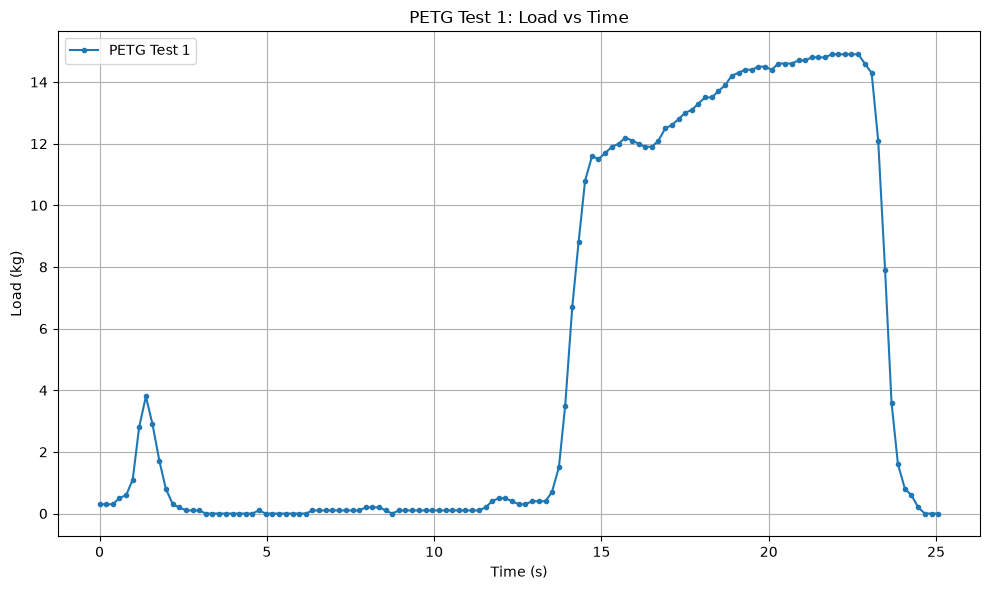

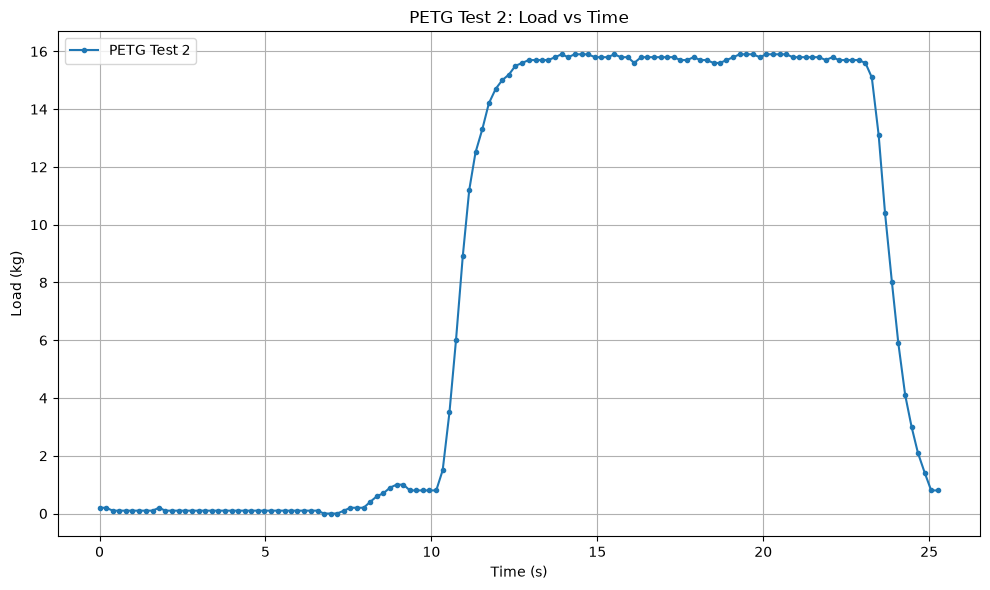

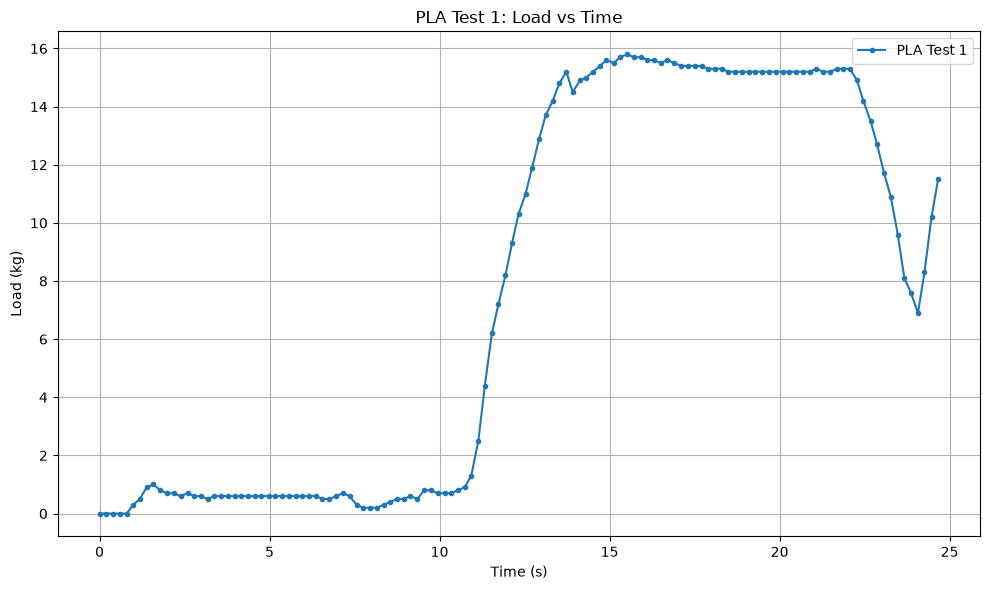

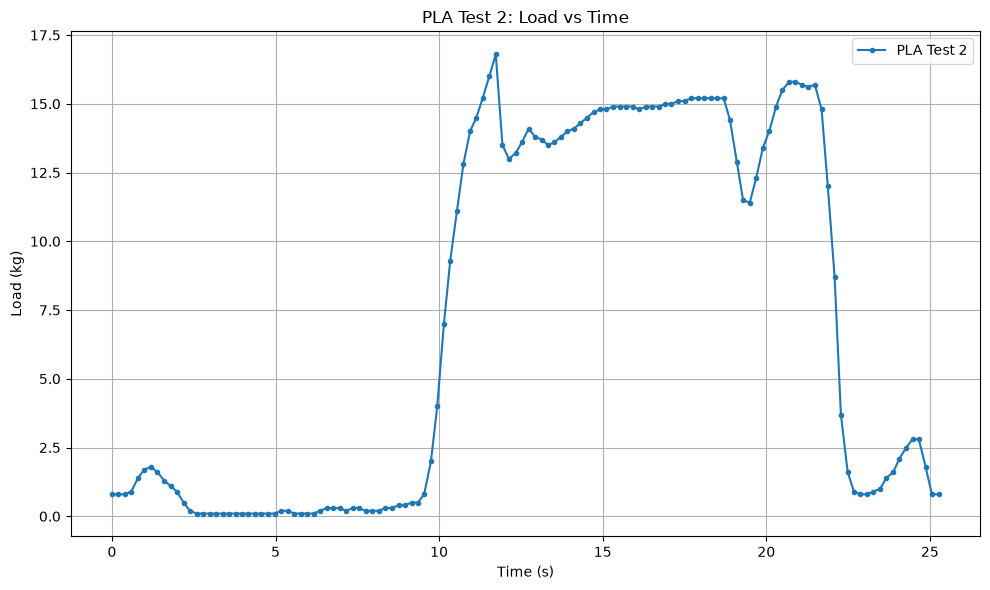

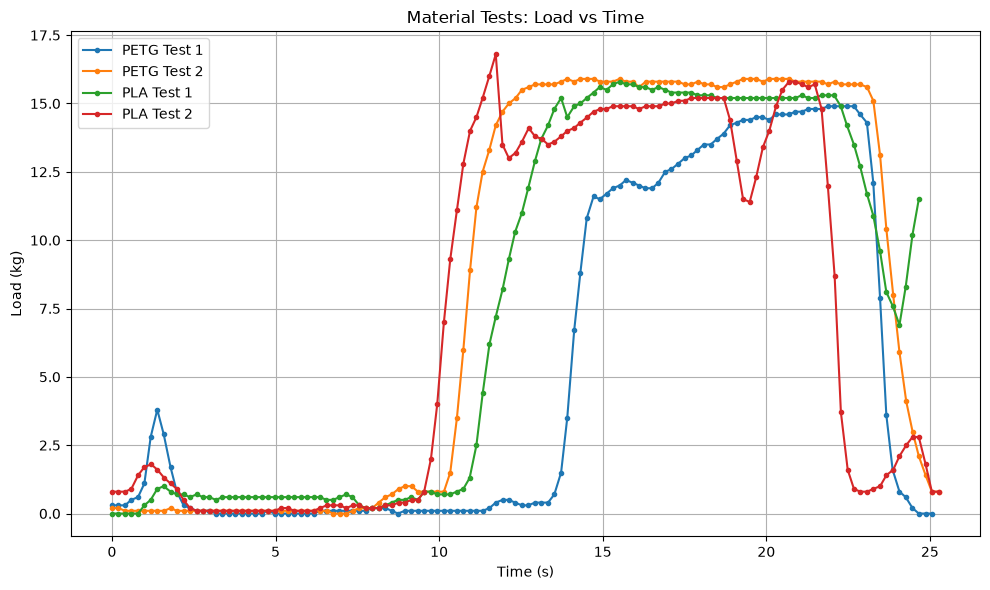

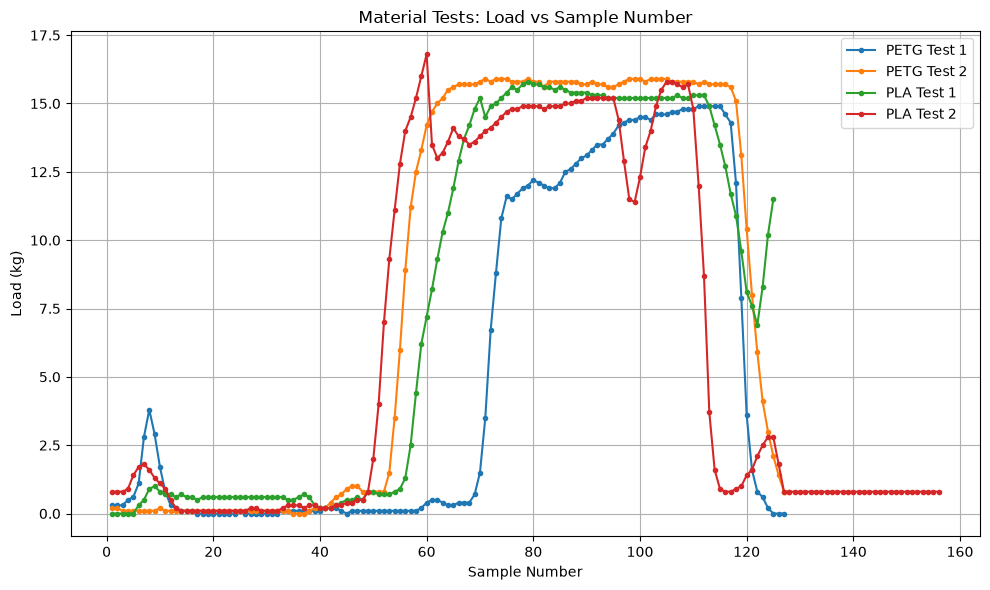

In [3]:
# ============================================================
# 1. Load the CSV files
# ============================================================

PETGTest1 = pd.read_csv("Data/PETG_Test1.csv")
PETGTest2 = pd.read_csv("Data/PETG_Test2.csv")
PLATest1 = pd.read_csv("Data/PLA_Test1.csv")
PLATest2 =  pd.read_csv("Data/PLA_Test2.csv")

# ============================================================
# 2. Convert timestamp to datetime
# ============================================================

PETGTest1["timestamp"] = pd.to_datetime(PETGTest1["timestamp"])
PETGTest2["timestamp"] = pd.to_datetime(PETGTest2["timestamp"])
PLATest1["timestamp"] = pd.to_datetime(PLATest1["timestamp"])
PLATest2["timestamp"] = pd.to_datetime(PLATest2["timestamp"])

# ============================================================
# 3. Calculate elapsed time from timestamp
# ============================================================

# This is preferable to the supplied elapsed_s column because
# the timestamp data covers the complete experiment.

PETGTest1["time_s"] = (PETGTest1["timestamp"] - PETGTest1["timestamp"].iloc[0]).dt.total_seconds()
PETGTest2["time_s"] = (PETGTest2["timestamp"] - PETGTest2["timestamp"].iloc[0]).dt.total_seconds()
PLATest1["time_s"] = (PETGTest1["timestamp"] - PETGTest1["timestamp"].iloc[0]).dt.total_seconds()
PLATest2["time_s"] = (PETGTest2["timestamp"] - PETGTest2["timestamp"].iloc[0]).dt.total_seconds()

# ============================================================
# 4. Display basic information
# ============================================================

print("PETG Test 1")
print(PETGTest1.head())
print(PETGTest1.describe())

print("\n PETG Test 2")
print(PETGTest2.head())
print(PETGTest2.describe())


print("\nPLA Test 1")
print(PLATest1.head())
print(PLATest1.describe())

print("\n PLA Test 2")
print(PLATest2.head())
print(PLATest2.describe())

# ============================================================
# 5. Maximum and minimum loads
# ============================================================

print("\nMaximum loads:")
print(f"PETG Test 1: {PETGTest1['load_kg'].max():.2f} kg")
print(f"PETG Test 2: {PETGTest2['load_kg'].max():.2f} kg")
print(f"PLA Test 1: {PLATest1['load_kg'].max():.2f} kg")
print(f"PLA Test 2: {PLATest2['load_kg'].max():.2f} kg")


print("\nMinimum loads:")
print(f"PETG Test 1: {PETGTest1['load_kg'].min():.2f} kg")
print(f"PETG Test 2: {PETGTest2['load_kg'].min():.2f} kg")
print(f"PLA Test 1: {PLATest1['load_kg'].min():.2f} kg")
print(f"PLA Test 2: {PLATest2['load_kg'].min():.2f} kg")


# ============================================================
# 6. Plot Test 1
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    PETGTest1["time_s"],
    PETGTest1["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 1"
)

plt.xlabel("Time (s)")
plt.ylabel("Load (kg)")
plt.title("PETG Test 1: Load vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


# ============================================================
# 7. Plot Test 2
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    PETGTest2["time_s"],
    PETGTest2["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 2"
)

plt.xlabel("Time (s)")
plt.ylabel("Load (kg)")
plt.title("PETG Test 2: Load vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

# Plot PLA TEst 1

plt.figure(figsize=(10, 6))

plt.plot(
    PLATest1["time_s"],
    PLATest1["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 1"
)

plt.xlabel("Time (s)")
plt.ylabel("Load (kg)")
plt.title("PLA Test 1: Load vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

#Plot PLA Test 2
 
plt.figure(figsize=(10, 6))

plt.plot(
    PLATest2["time_s"],
    PLATest2["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 2"
)

plt.xlabel("Time (s)")
plt.ylabel("Load (kg)")
plt.title("PLA Test 2: Load vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


# ============================================================
# 8. Compare both tests
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    PETGTest1["time_s"],
    PETGTest1["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 1"
)

plt.plot(
    PETGTest2["time_s"],
    PETGTest2["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 2"
)

plt.plot(
    PLATest1["time_s"],
    PLATest1["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 1"
)

plt.plot(
    PLATest2["time_s"],
    PLATest2["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 2"
)


plt.xlabel("Time (s)")
plt.ylabel("Load (kg)")
plt.title("Material Tests: Load vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


# ============================================================
# 9. Plot load against sample number
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    PETGTest1["sample_no"],
    PETGTest1["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 1"
)

plt.plot(
    PETGTest2["sample_no"],
    PETGTest2["load_kg"],
    marker="o",
    markersize=3,
    label="PETG Test 2"
)


plt.plot(
    PLATest1["sample_no"],
    PLATest1["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 1"
)

plt.plot(
    PLATest2["sample_no"],
    PLATest2["load_kg"],
    marker="o",
    markersize=3,
    label="PLA Test 2"
)


plt.xlabel("Sample Number")
plt.ylabel("Load (kg)")
plt.title("Material Tests: Load vs Sample Number")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()
